# H2 benchmark: EfficientSU2, UCCSD and fUCCSD with ZNE and CDR

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

## Setup

In [2]:
import contextlib
import io
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from pyscf import mcscf
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp
from slowquant.qiskit_interface.circuit_wavefunction import WaveFunctionCircuit
from slowquant.qiskit_interface.interface import QuantumInterface

from src.utils import load_config
from src.chem import get_molecule, get_problem, get_ansatz
from src.backend import run_vqe, get_transpiled
from src.mitigation import ZNE, CDR, M0

cfg = load_config("configs/h2.yaml")

molecule, mf, cas = get_molecule()
problem = get_problem()
e_nuc = molecule.energy_nuc()
mapper = JordanWignerMapper()

E_hf = mf.e_tot
E_fci = mcscf.CASCI(mf, cas[1], cas[0]).run().e_tot
print(f"HF  : {E_hf:.6f} Ha")
print(f"FCI : {E_fci:.6f} Ha")


Setting number of Numba threads to 1

HF  : -1.116999 Ha
FCI : -1.137306 Ha


## Ansatze

Each ansatz comes with its own Hamiltonian:

- **EfficientSU2, UCCSD** use the Qiskit Nature Hamiltonian.
- **fUCCSD** uses the Hamiltonian from SlowQuant's wavefunction, so it matches SlowQuant's orbitals.

UCCSD and fUCCSD start from θ = 0 (the HF state). EfficientSU2 starts from small random values, because θ = 0 is not the HF state for it.

In [3]:
ANSATZE = ["EfficientSU2", "UCCSD", "fUCCSD", "pp-tUPS"]
SEEDS = cfg["vqe"]["seeds"]
results = {name: {seed: {} for seed in SEEDS} for name in ANSATZE}

## VQE (noiseless) and transpiling

In [4]:
for name in ANSATZE:
    for seed in SEEDS:
        ansatz, hamiltonian, x0 = get_ansatz(name, seed)
        vqe_energy, theta_opt = run_vqe(ansatz, hamiltonian, x0)
        transpiled_ansatz, transpiled_hamiltonian = get_transpiled(ansatz, theta_opt, hamiltonian, seed)

        results[name][seed].update(ansatz=ansatz, hamiltonian=hamiltonian, theta_opt=theta_opt,
            transpiled_ansatz=transpiled_ansatz, transpiled_hamiltonian=transpiled_hamiltonian,
            E_exact=vqe_energy + e_nuc)
        print(f"{name:13s} seed={seed}  E_VQE = {vqe_energy + e_nuc:.6f}  "
              f"error vs FCI = {abs(vqe_energy + e_nuc - E_fci):.2e}  depth = {transpiled_ansatz.depth()}")

        print(f"seed : {seed}", len(results[name][seed]["theta_opt"]))

EfficientSU2  seed=37  E_VQE = -1.137306  error vs FCI = 1.77e-07  depth = 16
seed : 37 16
EfficientSU2  seed=42  E_VQE = -1.137306  error vs FCI = 2.64e-07  depth = 16
seed : 42 16
EfficientSU2  seed=99  E_VQE = -1.137306  error vs FCI = 9.77e-08  depth = 16
seed : 99 16
EfficientSU2  seed=200  E_VQE = -1.117002  error vs FCI = 2.03e-02  depth = 16
seed : 200 16
UCCSD         seed=37  E_VQE = -1.137306  error vs FCI = 5.75e-11  depth = 136
seed : 37 3


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


UCCSD         seed=42  E_VQE = -1.137306  error vs FCI = 5.75e-11  depth = 136
seed : 42 3
UCCSD         seed=99  E_VQE = -1.137306  error vs FCI = 5.75e-11  depth = 136
seed : 99 3
UCCSD         seed=200  E_VQE = -1.137306  error vs FCI = 5.75e-11  depth = 136
seed : 200 3
fUCCSD        seed=37  E_VQE = -1.137306  error vs FCI = 5.76e-11  depth = 53
seed : 37 3
fUCCSD        seed=42  E_VQE = -1.137306  error vs FCI = 5.76e-11  depth = 53
seed : 42 3
fUCCSD        seed=99  E_VQE = -1.137306  error vs FCI = 5.76e-11  depth = 53
seed : 99 3
fUCCSD        seed=200  E_VQE = -1.137306  error vs FCI = 5.76e-11  depth = 53
seed : 200 3
pp-tUPS       seed=37  E_VQE = -1.137306  error vs FCI = 5.69e-11  depth = 54
seed : 37 3
pp-tUPS       seed=42  E_VQE = -1.137306  error vs FCI = 5.69e-11  depth = 54
seed : 42 3
pp-tUPS       seed=99  E_VQE = -1.137306  error vs FCI = 5.69e-11  depth = 54
seed : 99 3
pp-tUPS       seed=200  E_VQE = -1.137306  error vs FCI = 5.69e-11  depth = 54
seed : 200 3


## ZNE

In [5]:
date = datetime.now().strftime("%Y-%m-%d")

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        zne = ZNE(seed)
        zne.run(r["transpiled_ansatz"], r["transpiled_hamiltonian"], e_nuc)
        zne.save(f"data/H2_{name}_ZNE_seed{seed}_{date}.npz")
        r["zne"] = zne
        r["E_noisy"] = zne.energies[0]

EfficientSU2 | linear  mean R² = 0.999921
EfficientSU2 | poly    mean R² = 1.000000
EfficientSU2 | exp     mean R² = 0.999998
UCCSD | linear  mean R² = 0.990103
UCCSD | poly    mean R² = 1.000000
UCCSD | exp     mean R² = 0.999769
fUCCSD | linear  mean R² = 0.996248
fUCCSD | poly    mean R² = 1.000000
fUCCSD | exp     mean R² = 0.999993
pp-tUPS | linear  mean R² = 0.996182
pp-tUPS | poly    mean R² = 1.000000
pp-tUPS | exp     mean R² = 0.999996


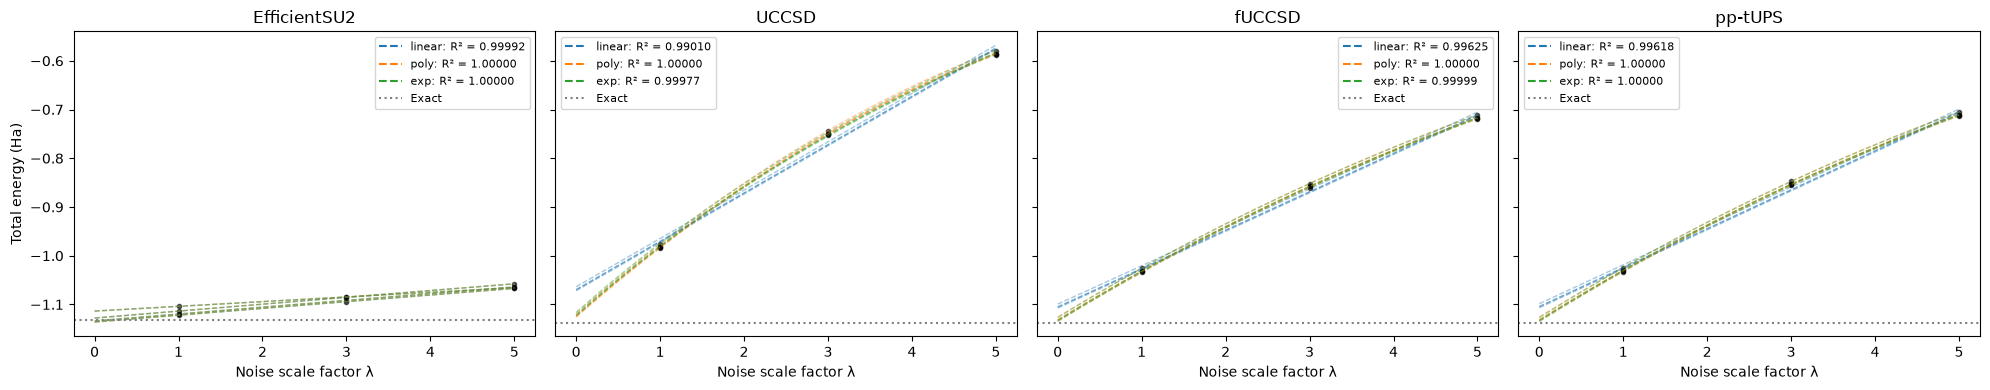

In [6]:
METHODS = ["linear", "poly", "exp"]
COLORS = {"linear": "tab:blue", "poly": "tab:orange", "exp": "tab:green"}
x = np.linspace(0, max(ZNE(SEEDS[0]).noise_factors), 100)

fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4), sharey=True)
for ax, name in zip(axes, ANSATZE):
    for seed in SEEDS:
        zne = results[name][seed]["zne"]
        ax.plot(zne.lambdas, zne.energies, "ko", ms=3, alpha=0.6)
        for m in METHODS:
            _, curve = zne.extrapolate(m)
            ax.plot(x, [curve(xi) for xi in x], "--", color=COLORS[m], alpha=0.4, lw=1)
    for m in METHODS:
        r2 = np.mean([results[name][s]["zne"].r_squared(m) for s in SEEDS])
        print(f"{name} | {m:6s}  mean R² = {r2:.6f}")
        ax.plot([], [], "--", color=COLORS[m], label=f"{m}: R² = {r2:.5f}")
    ax.axhline(np.mean([results[name][s]["E_exact"] for s in SEEDS]), color="gray", ls=":", label="Exact")
    ax.set_title(name); ax.set_xlabel("Noise scale factor λ"); ax.legend(fontsize=8)
axes[0].set_ylabel("Total energy (Ha)")
plt.tight_layout(); plt.show()


EfficientSU2 | linear  mean R² = 0.999921
EfficientSU2 | poly    mean R² = 1.000000
EfficientSU2 | exp     mean R² = 0.999998


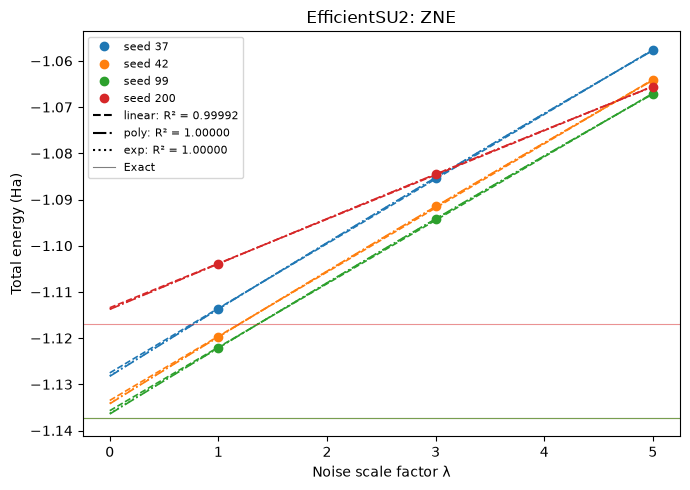

UCCSD | linear  mean R² = 0.990103
UCCSD | poly    mean R² = 1.000000
UCCSD | exp     mean R² = 0.999769


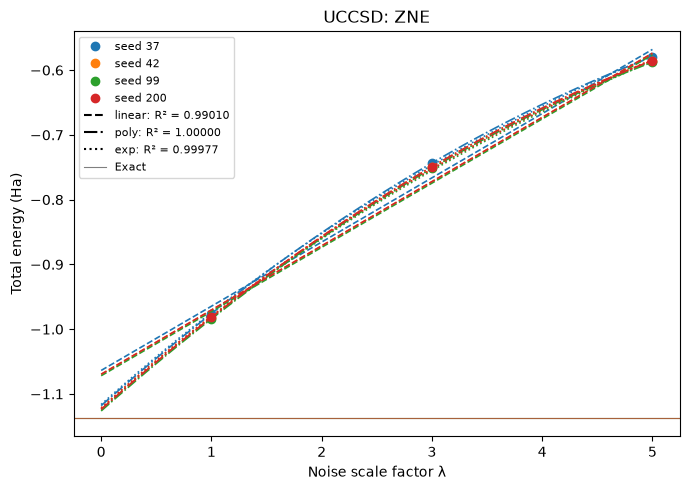

fUCCSD | linear  mean R² = 0.996248
fUCCSD | poly    mean R² = 1.000000
fUCCSD | exp     mean R² = 0.999993


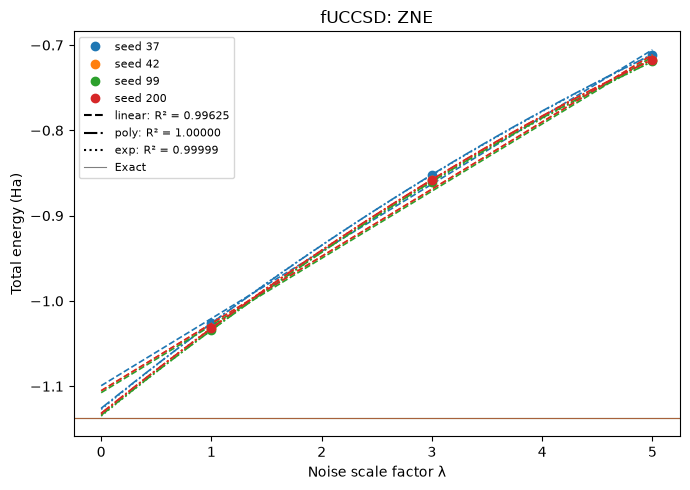

pp-tUPS | linear  mean R² = 0.996182
pp-tUPS | poly    mean R² = 1.000000
pp-tUPS | exp     mean R² = 0.999996


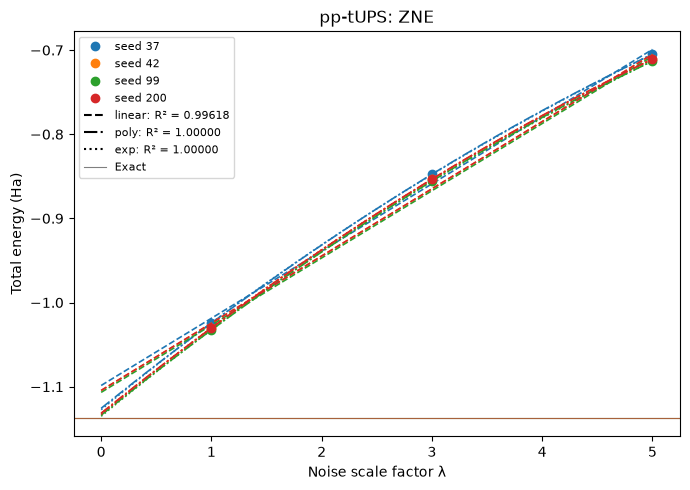

In [7]:
METHODS = ["linear", "poly", "exp"]
STYLES = {"linear": "--", "poly": "-.", "exp": ":"}
x = np.linspace(0, max(ZNE(SEEDS[0]).noise_factors), 100) 

for name in ANSATZE:
    fig, ax = plt.subplots(figsize=(7, 5))

    for i, seed in enumerate(SEEDS):
        zne = results[name][seed]["zne"]
        c = f"C{i}"
        ax.plot(zne.lambdas, zne.energies, "o", color=c, label=f"seed {seed}")
        for m in METHODS:
            _, curve = zne.extrapolate(m)
            ax.plot(x, [curve(xi) for xi in x], STYLES[m], color=c, lw=1.2)
        ax.axhline(results[name][seed]["E_exact"], color=c, lw=0.8, alpha=0.5)

    # legend entries for the line styles, with the mean R² over seeds
    for m in METHODS:
        r2 = np.mean([results[name][s]["zne"].r_squared(m) for s in SEEDS])
        print(f"{name} | {m:6s}  mean R² = {r2:.6f}")
        ax.plot([], [], STYLES[m], color="k", label=f"{m}: R² = {r2:.5f}")
    ax.plot([], [], "-", color="k", lw=0.8, alpha=0.5, label="Exact")

    ax.set_title(f"{name}: ZNE")
    ax.set_xlabel("Noise scale factor λ")
    ax.set_ylabel("Total energy (Ha)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


In [8]:
METHODS = ["linear", "poly", "exp"]

def distance_to_one(r2):
    return np.inf if np.isnan(r2) else abs(1 - r2)       # a NaN R² is never picked

print(f"{'Ansatz':13s} {'seed':>5s} " + " ".join(f"{m:>10s}" for m in METHODS) + "   best     ZNE error (Ha)")
for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        r2 = {m: r["zne"].r_squared(m) for m in METHODS}
        best = min(METHODS, key=lambda m: distance_to_one(r2[m]))     # R² closest to 1

        r["zne_method"] = best
        r["E_zne"], _ = r["zne"].extrapolate(best)
        print(f"{name:13s} {seed:5d} " + " ".join(f"{r2[m]:10.6f}" for m in METHODS)
              + f"   {best:6s}   {abs(r['E_zne'] - r['E_exact']):.2e}")



Ansatz         seed     linear       poly        exp   best     ZNE error (Ha)
EfficientSU2     37   0.999909   1.000000   0.999998   poly     9.04e-03
EfficientSU2     42   0.999911   1.000000   0.999998   poly     3.10e-03
EfficientSU2     99   0.999909   1.000000   0.999997   poly     8.82e-04
EfficientSU2    200   0.999956   1.000000   0.999999   poly     3.23e-03
UCCSD            37   0.990103   1.000000   0.999787   poly     1.92e-02
UCCSD            42   0.990103   1.000000   0.999765   poly     1.32e-02
UCCSD            99   0.990103   1.000000   0.999756   poly     1.10e-02
UCCSD           200   0.990103   1.000000   0.999765   poly     1.33e-02
fUCCSD           37   0.996248   1.000000   0.999995   poly     1.15e-02
fUCCSD           42   0.996248   1.000000   0.999993   poly     5.51e-03
fUCCSD           99   0.996248   1.000000   0.999992   poly     3.29e-03
fUCCSD          200   0.996248   1.000000   0.999993   poly     5.61e-03
pp-tUPS          37   0.996182   1.000000   0

Choose the extrapolation for each ansatz from the plots:

In [9]:
METHODS = ["linear", "poly", "exp"]
zne_method = {name: {} for name in ANSATZE}       # zne_method[name][seed], filled at run time

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        r2 = {m: r["zne"].r_squared(m) for m in METHODS}
        method = min(METHODS, key=lambda m: np.inf if np.isnan(r2[m]) else abs(1 - r2[m]))

        zne_method[name][seed] = method
        r["E_zne"], _ = r["zne"].extrapolate(method)
        print(f"{name:13s} ({method:6s}) Seed = {seed}  Noisy error = {abs(r['E_noisy'] - r['E_exact']):.6f}   "
              f"ZNE error = {abs(r['E_zne'] - r['E_exact']):.6f} Ha   "
              f"R² = " + " ".join(f"{m}:{r2[m]:.5f}" for m in METHODS))


EfficientSU2  (poly  ) Seed = 37  Noisy error = 0.023609   ZNE error = 0.009043 Ha   R² = linear:0.99991 poly:1.00000 exp:1.00000
EfficientSU2  (poly  ) Seed = 42  Noisy error = 0.017557   ZNE error = 0.003099 Ha   R² = linear:0.99991 poly:1.00000 exp:1.00000
EfficientSU2  (poly  ) Seed = 99  Noisy error = 0.015187   ZNE error = 0.000882 Ha   R² = linear:0.99991 poly:1.00000 exp:1.00000
EfficientSU2  (poly  ) Seed = 200  Noisy error = 0.013090   ZNE error = 0.003230 Ha   R² = linear:0.99996 poly:1.00000 exp:1.00000
UCCSD         (poly  ) Seed = 37  Noisy error = 0.161248   ZNE error = 0.019175 Ha   R² = linear:0.99010 poly:1.00000 exp:0.99979
UCCSD         (poly  ) Seed = 42  Noisy error = 0.155296   ZNE error = 0.013223 Ha   R² = linear:0.99010 poly:1.00000 exp:0.99976
UCCSD         (poly  ) Seed = 99  Noisy error = 0.153074   ZNE error = 0.011001 Ha   R² = linear:0.99010 poly:1.00000 exp:0.99976
UCCSD         (poly  ) Seed = 200  Noisy error = 0.155392   ZNE error = 0.013319 Ha   R² 

## CDR

In [10]:
for name in ANSATZE:
    for seed in SEEDS:
        print(f"{name}\n")
        r = results[name][seed]
        cdr = CDR(seed)
        circuits = cdr.training_circuits(r["transpiled_ansatz"])
        cdr.training_data(circuits, r["hamiltonian"], e_nuc)      # LiH: keep transpiled=True
        cdr.save(f"data/H2_{name}_CDR_seed{seed}_{date}.npz")
        r["cdr"] = cdr

EfficientSU2

Seed = 37 n = 19 non-Clifford gates, k = 2 -> C(n, k) = 171
EfficientSU2

Seed = 42 n = 17 non-Clifford gates, k = 2 -> C(n, k) = 136
EfficientSU2

Seed = 99 n = 19 non-Clifford gates, k = 2 -> C(n, k) = 171
EfficientSU2

Seed = 200 n = 19 non-Clifford gates, k = 2 -> C(n, k) = 171
UCCSD

Seed = 37 n = 8 non-Clifford gates, k = 2 -> C(n, k) = 28
UCCSD

Seed = 42 n = 8 non-Clifford gates, k = 2 -> C(n, k) = 28
UCCSD

Seed = 99 n = 8 non-Clifford gates, k = 2 -> C(n, k) = 28
UCCSD

Seed = 200 n = 8 non-Clifford gates, k = 2 -> C(n, k) = 28
fUCCSD

Seed = 37 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
fUCCSD

Seed = 42 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
fUCCSD

Seed = 99 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
fUCCSD

Seed = 200 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
pp-tUPS

Seed = 37 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
pp-tUPS

Seed = 42 n = 10 non-Clifford gates, k = 2 -> C(n, k) = 45
pp-tUPS

Seed = 99 n = 10 non-Cliffor

To skip the slow part later, load saved training data instead:

```python
cdr = CDR()
cdr.load("data/H2_fUCCSD_CDR_<date>.npz")
results["fUCCSD"]["cdr"] = cdr
```

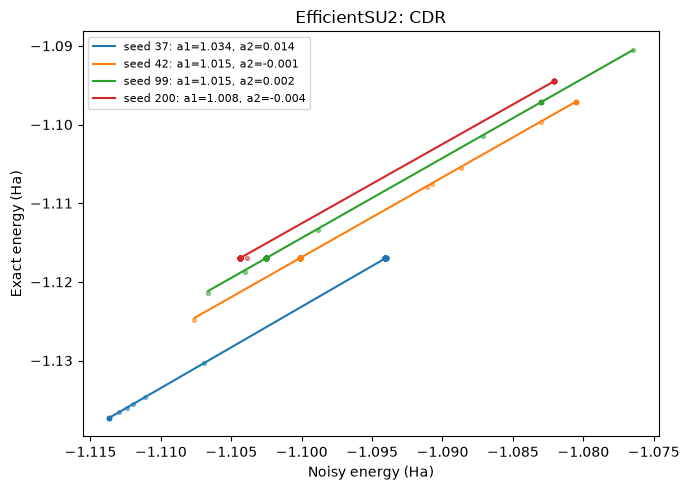

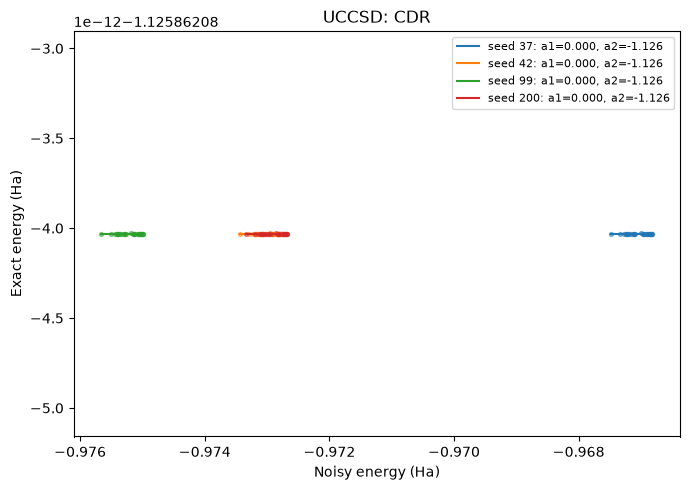

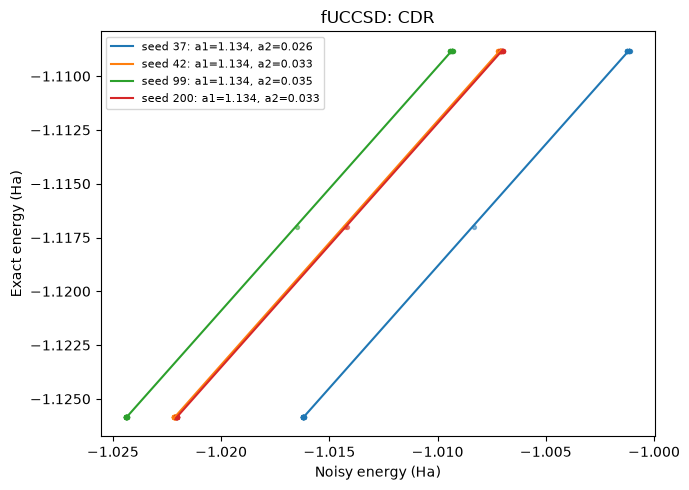

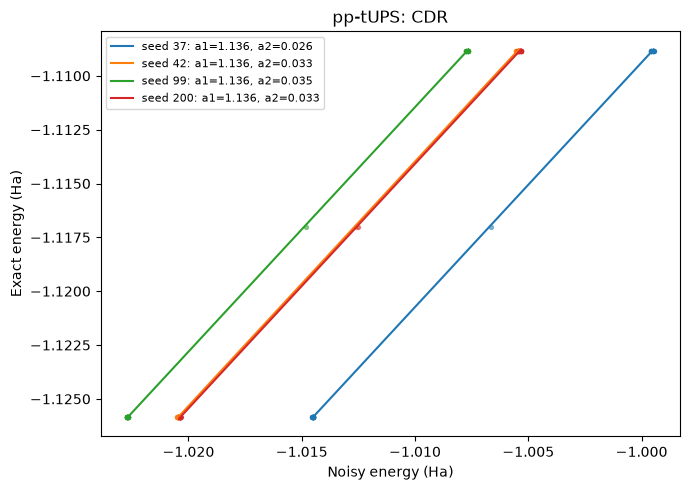

In [11]:
for name in ANSATZE:
    fig, ax = plt.subplots(figsize=(7, 5))

    for i, seed in enumerate(SEEDS):
        r = results[name][seed]; cdr = r["cdr"]
        a1, a2 = cdr.fit()
        r["E_cdr"] = float(cdr.mitigate(r["E_noisy"]))
        x = np.linspace(cdr.X_noisy.min(), cdr.X_noisy.max(), 100)
        ax.scatter(cdr.X_noisy, cdr.X_exact, s=8, color=f"C{i}", alpha=0.5)
        ax.plot(x, cdr.mitigate(x), "-", color=f"C{i}", label=f"seed {seed}: a1={a1:.3f}, a2={a2:.3f}")

    ax.set_title(f"{name}: CDR")
    ax.set_xlabel("Noisy energy (Ha)")
    ax.set_ylabel("Exact energy (Ha)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"plots/H2_CDR_{name}_{date}.png", dpi=200)
    plt.show()


## M0

In [12]:
M0_ANSATZE = ["fUCCSD", "pp-tUPS"]   # M0 only works with SlowQuant ansatze

for name in ANSATZE:
    for seed in SEEDS:
        r = results[name][seed]
        if name in M0_ANSATZE:
            r["E_noisy_m0"], r["E_m0"] = M0(seed).run(name, r["theta_opt"])
            print(f"{name:13s} Seed = {seed}  Noisy (sampler) error = {abs(r['E_noisy_m0'] - r['E_exact']):.6f}   "
                  f"M0 error = {abs(r['E_m0'] - r['E_exact']):.6f} Ha")
        else:
            r["E_noisy_m0"] = r["E_m0"] = np.nan


fUCCSD        Seed = 37  Noisy (sampler) error = 0.157620   M0 error = 0.002131 Ha
fUCCSD        Seed = 42  Noisy (sampler) error = 0.132825   M0 error = 0.004043 Ha
fUCCSD        Seed = 99  Noisy (sampler) error = 0.171155   M0 error = 0.000825 Ha
fUCCSD        Seed = 200  Noisy (sampler) error = 0.155321   M0 error = 0.002895 Ha
pp-tUPS       Seed = 37  Noisy (sampler) error = 0.198309   M0 error = 0.000514 Ha
pp-tUPS       Seed = 42  Noisy (sampler) error = 0.145515   M0 error = 0.001899 Ha
pp-tUPS       Seed = 99  Noisy (sampler) error = 0.197202   M0 error = 0.002181 Ha
pp-tUPS       Seed = 200  Noisy (sampler) error = 0.193504   M0 error = 0.004570 Ha


## Summary

In [13]:
def errs(name, key):
    return np.array([abs(results[name][s][key] - results[name][s]["E_exact"]) for s in SEEDS])

keys = ("E_noisy", "E_zne", "E_cdr", "E_m0")

print(f"{'Ansatz':13s} {'err Noisy':>22s} {'err ZNE':>22s} {'err CDR':>22s} {'err M0':>22s}")
for name in ANSATZE:
    cells = []
    for k in keys:
        e = errs(name, k)
        cells.append(f"{'-':>22s}" if np.isnan(e).all() else f"{e.mean():10.2e} ± {e.std():8.2e}")
    print(f"{name:13s} " + " ".join(cells))


Ansatz                     err Noisy                err ZNE                err CDR                 err M0
EfficientSU2    1.74e-02 ± 3.94e-03   4.06e-03 ± 3.02e-03   3.36e-04 ± 1.94e-04                      -
UCCSD           1.56e-01 ± 3.03e-03   1.42e-02 ± 3.03e-03   1.14e-02 ± 4.58e-16                      -
fUCCSD          1.06e-01 ± 3.03e-03   6.47e-03 ± 3.03e-03   1.74e-04 ± 1.84e-16   2.47e-03 ± 1.17e-03
pp-tUPS         1.08e-01 ± 3.03e-03   6.62e-03 ± 3.03e-03   2.24e-04 ± 5.98e-16   2.29e-03 ± 1.46e-03


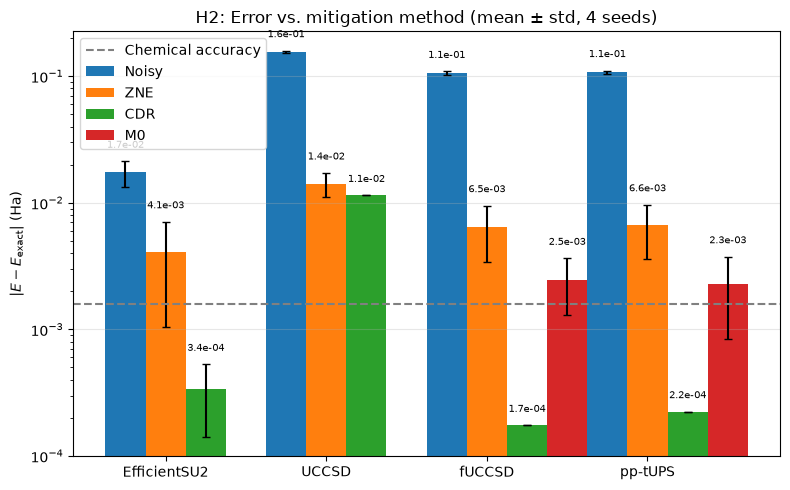

In [14]:
import numpy as np
import matplotlib.pyplot as plt

methods = [("E_noisy", "Noisy"), ("E_zne", "ZNE"), ("E_cdr", "CDR"), ("E_m0", "M0")]
w = 0.25
x = np.arange(len(ANSATZE))

def errs(name, key):
    """|E - E_exact| for every seed of one ansatz."""
    return np.array([abs(results[name][s][key] - results[name][s]["E_exact"]) for s in SEEDS])

fig, ax = plt.subplots(figsize=(8, 5))
for i, (key, label) in enumerate(methods):
    mean = np.array([errs(n, key).mean() for n in ANSATZE])
    std = np.array([errs(n, key).std() for n in ANSATZE])
    lower = np.minimum(std, 0.9 * mean)          # keeps the lower error bar positive on the log axis
    bars = ax.bar(x + (i - 1) * w, mean, w, yerr=[lower, std], capsize=3, label=label)
    ax.bar_label(bars, labels=[f"{m:.1e}" for m in mean], fontsize=7, padding=8)

plt.axhline(1.6e-3, color="gray", ls="--", label="Chemical accuracy")

ax.set_xticks(x)
ax.set_xticklabels(ANSATZE)
ax.set_ylabel(r"$|E - E_\mathrm{exact}|$ (Ha)")
ax.set_yscale("log")
ax.set_title(f"H2: Error vs. mitigation method (mean ± std, {len(SEEDS)} seeds)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"plots/H2_mitigation_errors_{date}.png", dpi=200)
plt.show()
